# MOTOR INSURANCE CLAIM PRIDICTION 
The purpose of this project is to predict whether a motor insurance customer will make a claim or not using machine learning techniques. By analyzing customer and vehicle information, the model helps insurance companies identify high-risk customers and make better decisions in policy pricing and risk management. This improves efficiency and reduces financial losses for the insurance company.

#import Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import joblib



Load Dataset

In [2]:
df=pd.read_csv(r"C:\Project\Motor_Insurance_Claim_Prediction_Project_Dataset_Copy.csv")

Basic Data Understanding

In [3]:
df.shape

(7000, 19)

In [4]:
df.head()

,Customer_ID,Age,Gender,Region,Annual_Income,Driving_Experience_Years,Vehicle_Age,Vehicle_Type,Engine_Capacity,Vehicle_Value,Policy_Type,Policy_Tenure,Premium_Amount,Deductible,No_Claim_Bonus,Previous_Accidents,Traffic_Violations,Credit_Score,Claim_Status
0,CUST0001,42,Male,Rural,1334033.0,11,14,Sedan,2364.0,1200853.0,Third Party,3,47537.0,1456.0,13,2,3.0,373.0,No Claim
1,CUST0002,63,Female,Semi-Urban,1894537.0,14,10,SUV,1698.0,1154032.0,Third Party,1,43636.0,NaN,9,2,1.0,594.0,Claim
2,CUST0003,51,Female,Rural,465972.0,1,0,Truck,1904.0,859119.0,Comprehensive,1,NaN,7436.0,33,3,8.0,628.0,No Claim
3,CUST0004,24,Female,Semi-Urban,841147.0,17,9,Truck,2412.0,1499529.0,Third Party,4,16595.0,2573.0,15,4,8.0,NaN,No Claim
4,CUST0005,18,Female,Rural,1892110.0,27,12,NaN,1070.0,633245.0,Third Party,1,21205.0,9399.0,6,3,0.0,744.0,No Claim


In [5]:
df.tail()

,Customer_ID,Age,Gender,Region,Annual_Income,Driving_Experience_Years,Vehicle_Age,Vehicle_Type,Engine_Capacity,Vehicle_Value,Policy_Type,Policy_Tenure,Premium_Amount,Deductible,No_Claim_Bonus,Previous_Accidents,Traffic_Violations,Credit_Score,Claim_Status
6995,CUST6996,39,Male,Semi-Urban,1939080.0,9,11,Truck,1597.0,1369412.0,Comprehensive,2,17397.0,1916.0,44,1,NaN,762.0,No Claim
6996,CUST6997,51,Female,Rural,1401838.0,31,7,Hatchback,2409.0,1301507.0,Third Party,3,23722.0,5187.0,47,2,8.0,416.0,No Claim
6997,CUST6998,29,Male,Rural,820399.0,3,2,SUV,2012.0,857373.0,Comprehensive,1,44098.0,3415.0,28,0,7.0,519.0,No Claim
6998,CUST6999,18,Male,Semi-Urban,1179448.0,17,9,Truck,1037.0,873722.0,Comprehensive,4,40477.0,2188.0,13,3,6.0,597.0,Claim
6999,CUST7000,48,Female,Semi-Urban,1726658.0,16,11,Truck,1165.0,889872.0,Third Party,3,NaN,5408.0,11,4,4.0,667.0,No Claim


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer_ID               7000 non-null   object 
 1   Age                       7000 non-null   int64  
 2   Gender                    7000 non-null   object 
 3   Region                    6718 non-null   object 
 4   Annual_Income             6500 non-null   float64
 5   Driving_Experience_Years  7000 non-null   int64  
 6   Vehicle_Age               7000 non-null   int64  
 7   Vehicle_Type              6590 non-null   object 
 8   Engine_Capacity           6739 non-null   float64
 9   Vehicle_Value             6943 non-null   float64
 10  Policy_Type               6940 non-null   object 
 11  Policy_Tenure             7000 non-null   int64  
 12  Premium_Amount            6125 non-null   float64
 13  Deductible                6557 non-null   float64
 14  No_Claim

In [7]:
df.describe()

,Age,Annual_Income,Driving_Experience_Years,Vehicle_Age,Engine_Capacity,Vehicle_Value,Policy_Tenure,Premium_Amount,Deductible,No_Claim_Bonus,Previous_Accidents,Traffic_Violations,Credit_Score
count,7000.000000,6.500000e+03,7000.000000,7000.000000,6739.000000,6.943000e+03,7000.000000,6.125000e+03,6557.000000,7000.000000,7000.000000,6583.000000,6178.000000
mean,43.838857,1.414093e+06,19.566000,7.254000,1888.287580,1.310654e+06,2.491714,3.379708e+04,5456.474912,24.434429,2.052286,4.570561,570.802363
std,15.000596,2.554621e+06,11.533631,4.366749,624.807649,1.557461e+06,1.125597,5.822791e+04,2639.891699,14.093872,1.414863,2.835910,159.067333
min,18.000000,2.074610e+05,0.000000,0.000000,801.000000,3.016200e+05,1.000000,5.002000e+03,1007.000000,0.000000,0.000000,0.000000,300.000000
25%,31.000000,6.706700e+05,10.000000,4.000000,1345.000000,7.598220e+05,1.000000,1.617300e+04,2960.000000,13.000000,1.000000,2.000000,437.000000
50%,44.000000,1.129044e+06,20.000000,7.000000,1891.000000,1.181809e+06,2.000000,2.670200e+04,5511.000000,24.000000,2.000000,5.000000,562.000000
75%,56.000000,1.606368e+06,29.000000,11.000000,2401.000000,1.624452e+06,4.000000,3.934600e+04,7704.000000,37.000000,3.000000,7.000000,709.000000
max,69.000000,1.324309e+08,39.000000,14.000000,2987.000000,2.345255e+07,4.000000,1.951105e+06,9994.000000,49.000000,4.000000,9.000000,849.000000


Checking Duplicate Values

In [8]:
df.duplicated().sum()

np.int64(0)

Checking Missing Values

In [9]:
df.isna().sum()

Customer_ID                   0
Age                           0
Gender                        0
Region                      282
Annual_Income               500
Driving_Experience_Years      0
Vehicle_Age                   0
Vehicle_Type                410
Engine_Capacity             261
Vehicle_Value                57
Policy_Type                  60
Policy_Tenure                 0
Premium_Amount              875
Deductible                  443
No_Claim_Bonus                0
Previous_Accidents            0
Traffic_Violations          417
Credit_Score                822
Claim_Status                  0
dtype: int64

Remove unnecessary columns

In [10]:
df=df.drop("Customer_ID", axis=1)

Identify Numerical and Categorical Columns

In [11]:
num_col = df.select_dtypes(exclude=['object','string']).columns
cat_col = df.select_dtypes(include=['object','string']).columns

In [12]:
num_col

Index(['Age', 'Annual_Income', 'Driving_Experience_Years', 'Vehicle_Age',
       'Engine_Capacity', 'Vehicle_Value', 'Policy_Tenure', 'Premium_Amount',
       'Deductible', 'No_Claim_Bonus', 'Previous_Accidents',
       'Traffic_Violations', 'Credit_Score'],
      dtype='object')

In [13]:
cat_col

Index(['Gender', 'Region', 'Vehicle_Type', 'Policy_Type', 'Claim_Status'], dtype='object')

Outlier Detection using Box Plot

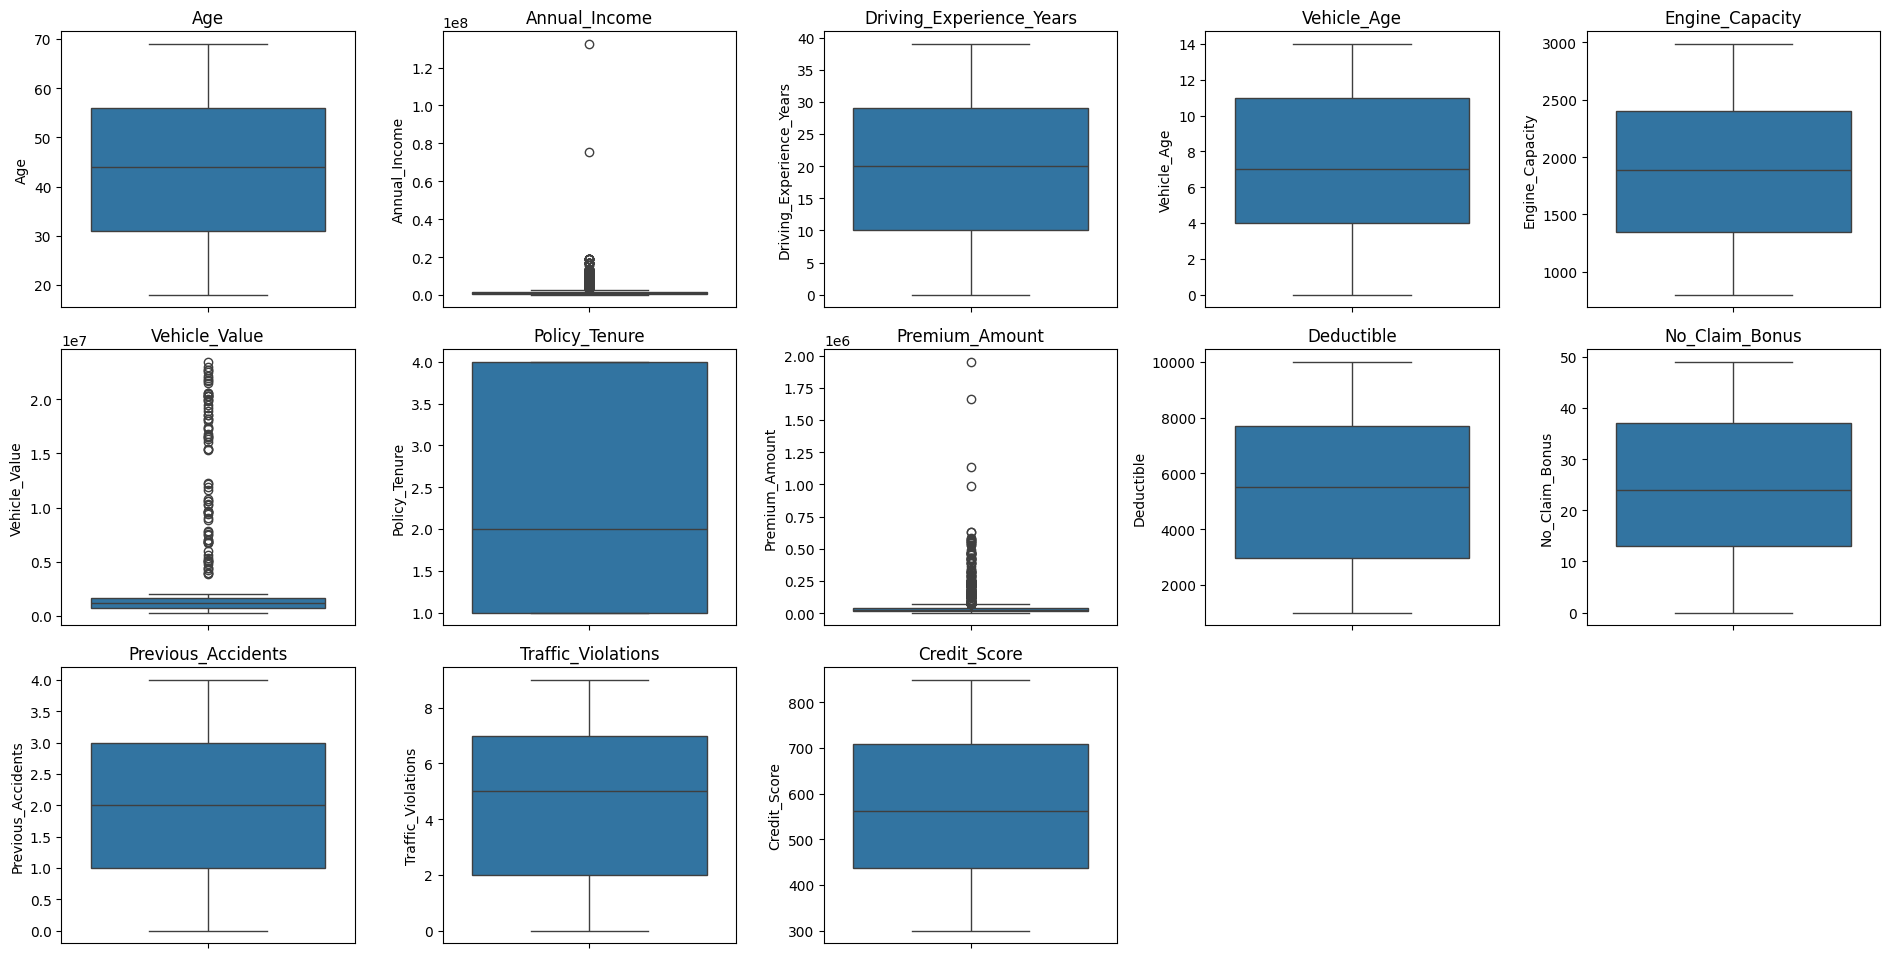

In [14]:
plt.figure(figsize=(19,16))
for i, col in enumerate(num_col,1):
    plt.subplot(5,5,i) 
    sns.boxplot(df[col], fill=True)
    plt.title(col)
plt.tight_layout()
plt.show()

Handling Missing Values in Numerical Columns

In [15]:
for col in num_col:
    if df[col].isnull().sum()>1:
        df[col]=df[col].fillna(df[col].median())

Checking Unique Values in Categorical Columns

In [16]:
for col in cat_col:
    print(f">>>>{col}<<<<")
    print(df[col].unique())
    print("=====================================")

>>>>Gender<<<<
['Male' 'Female']
>>>>Region<<<<
['Rural' 'Semi-Urban' 'Urban' nan]
>>>>Vehicle_Type<<<<
['Sedan' 'SUV' 'Truck' nan 'Hatchback']
>>>>Policy_Type<<<<
['Third Party' 'Comprehensive' nan]
>>>>Claim_Status<<<<
['No Claim' 'Claim']


Handling Missing Values in Categorical Columns

In [17]:
for col in cat_col:
    if df[col].isnull().sum()>1:
        df[col]=df[col].fillna(df[col].mode()[0])

Distribution Analysis of Numerical Features

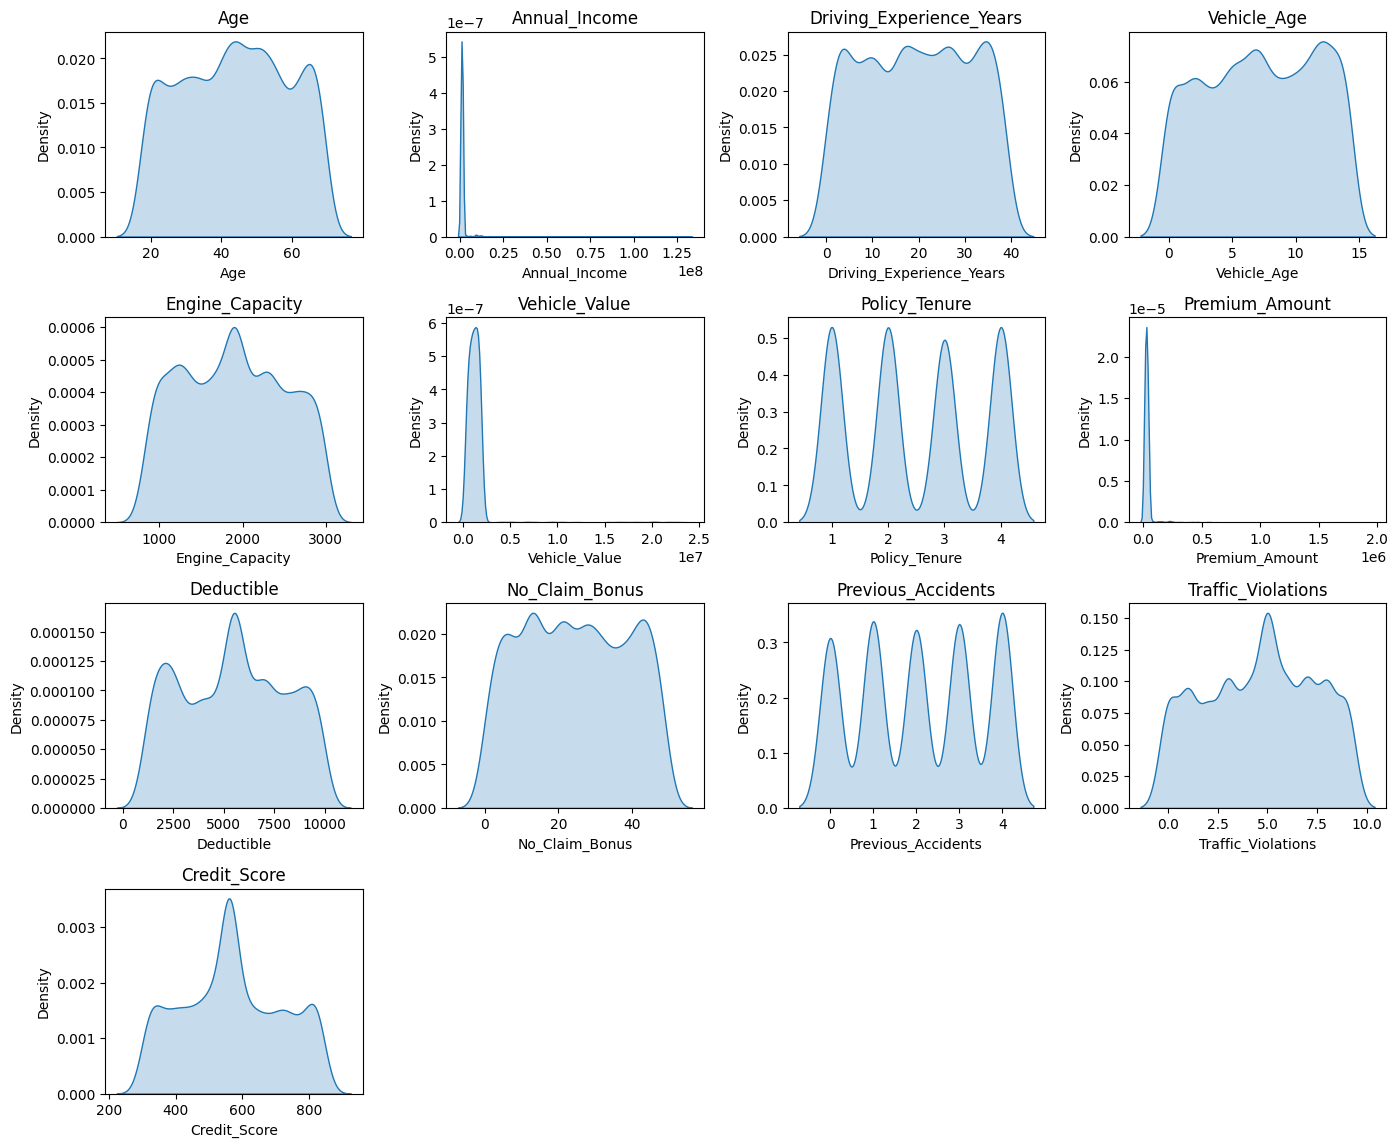

In [18]:

plt.figure(figsize=(14,14))

for i, col in enumerate(num_col,1):
    plt.subplot(5,4,i) 
    sns.kdeplot(df[col], fill=True)
    plt.title(col)
plt.tight_layout()
plt.show()

Skewness Analysis of Numerical Features

In [19]:
for col in num_col:
    print(f"{col}---->{df[col].skew()}")

Age---->-0.042493690823237576
Annual_Income---->27.352410789806655
Driving_Experience_Years---->-0.02429431951748872
Vehicle_Age---->-0.07636437768833731
Engine_Capacity---->0.04644968248951482
Vehicle_Value---->9.921974791195906
Policy_Tenure---->0.020336434560378
Premium_Amount---->15.660405343462163
Deductible---->0.002889732535468029
No_Claim_Bonus---->0.02065676596886028
Previous_Accidents---->-0.033742638863884344
Traffic_Violations---->-0.08218740518578664
Credit_Score---->0.07102436073950874


Distribution of Claim Status

Text(0.5, 1.0, 'Claim vs No Claim')

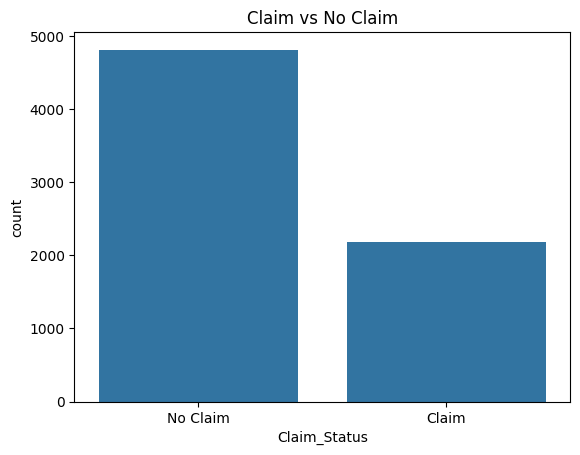

In [20]:
sns.countplot(x='Claim_Status', data=df)
plt.title('Claim vs No Claim')

Encoding the Target Variable (Claim_Status)

In [21]:
df['Claim_Status'] = df['Claim_Status'].map({'No Claim':0, 'Claim':1})

Correlation Heatmap

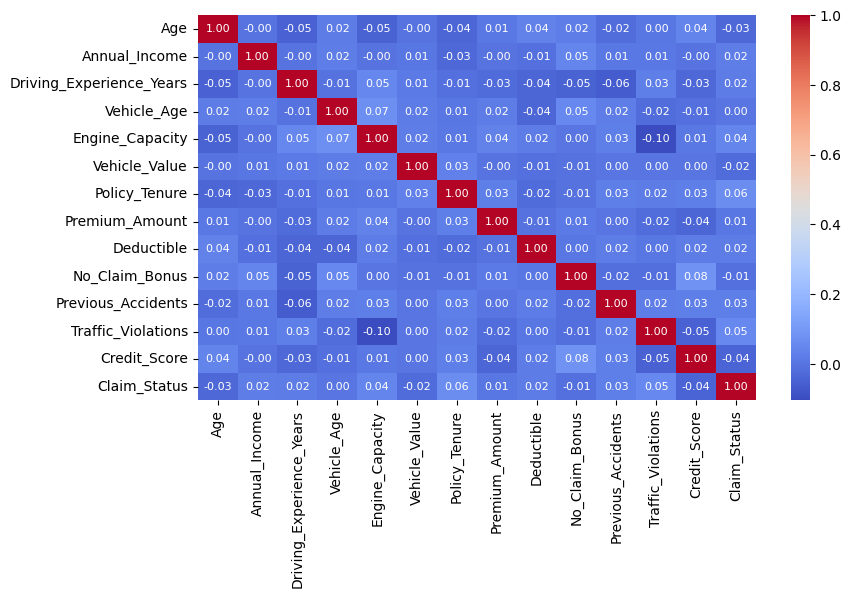

In [22]:
plt.figure(figsize=(9,5))
num_df=df.select_dtypes(include=["int64","float64"])
sns.heatmap(num_df.corr(),annot=True,cmap="coolwarm",fmt=".2f", annot_kws={"size":8})
plt.show()

Encoding Categorical Features

In [23]:
df['Gender'] = df['Gender'].map({'Male':1, 'Female':0})

In [24]:
df = pd.get_dummies(df, columns=['Region','Vehicle_Type','Policy_Type'], drop_first=True)

Separating Independent and Target columns

In [25]:
x=df.drop("Claim_Status", axis=1)
y=df["Claim_Status"]

Train-Test Split

In [26]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [27]:
x_train.columns

Index(['Age', 'Gender', 'Annual_Income', 'Driving_Experience_Years',
       'Vehicle_Age', 'Engine_Capacity', 'Vehicle_Value', 'Policy_Tenure',
       'Premium_Amount', 'Deductible', 'No_Claim_Bonus', 'Previous_Accidents',
       'Traffic_Violations', 'Credit_Score', 'Region_Semi-Urban',
       'Region_Urban', 'Vehicle_Type_SUV', 'Vehicle_Type_Sedan',
       'Vehicle_Type_Truck', 'Policy_Type_Third Party'],
      dtype='object')

Decision Tree Model Training

In [28]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)
dt_pred = dt.predict(x_test)

Random Forest Model Training

In [29]:
rf = RandomForestClassifier()
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_test)

XGBoost Model Training

In [30]:
xgb= XGBClassifier()
xgb.fit(x_train, y_train)
xgb_pred = xgb.predict(x_test)

Model Accuracy Evaluation

In [31]:
print("Decision Tree:", accuracy_score(y_test, dt_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))
print("XGBClassifier:",accuracy_score(y_test, xgb_pred))

Decision Tree: 0.9592857142857143
Random Forest: 0.9871428571428571
XGBClassifier: 0.985


Train vs Test Accuracy Comparison

In [32]:
train_pred = rf.predict(x_train)
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, rf_pred)
print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

Train Accuracy: 1.0
Test Accuracy: 0.9871428571428571


Model Prediction Performance (Confusion Matrix)

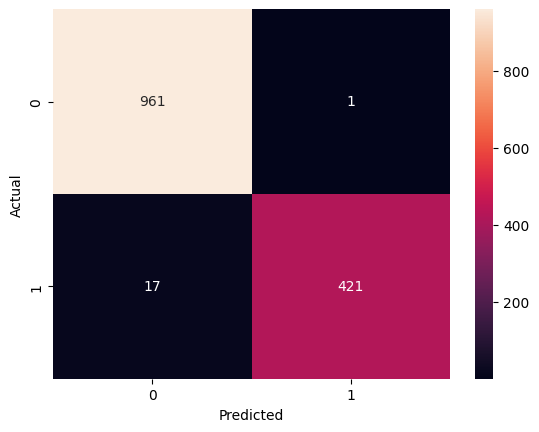

In [33]:
cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Saving Trained Model using Joblib

In [34]:
joblib.dump(rf, "motor_insurance_model.pkl")

['motor_insurance_model.pkl']

In [35]:
joblib.dump(x.columns.tolist(), "model_columns.pkl")

['model_columns.pkl']

In [36]:
print(rf.predict_proba(x_test[:5]))

[[0.11 0.89]
 [0.94 0.06]
 [0.13 0.87]
 [0.94 0.06]
 [0.98 0.02]]
